Saved: full_comparison_dashboard.png


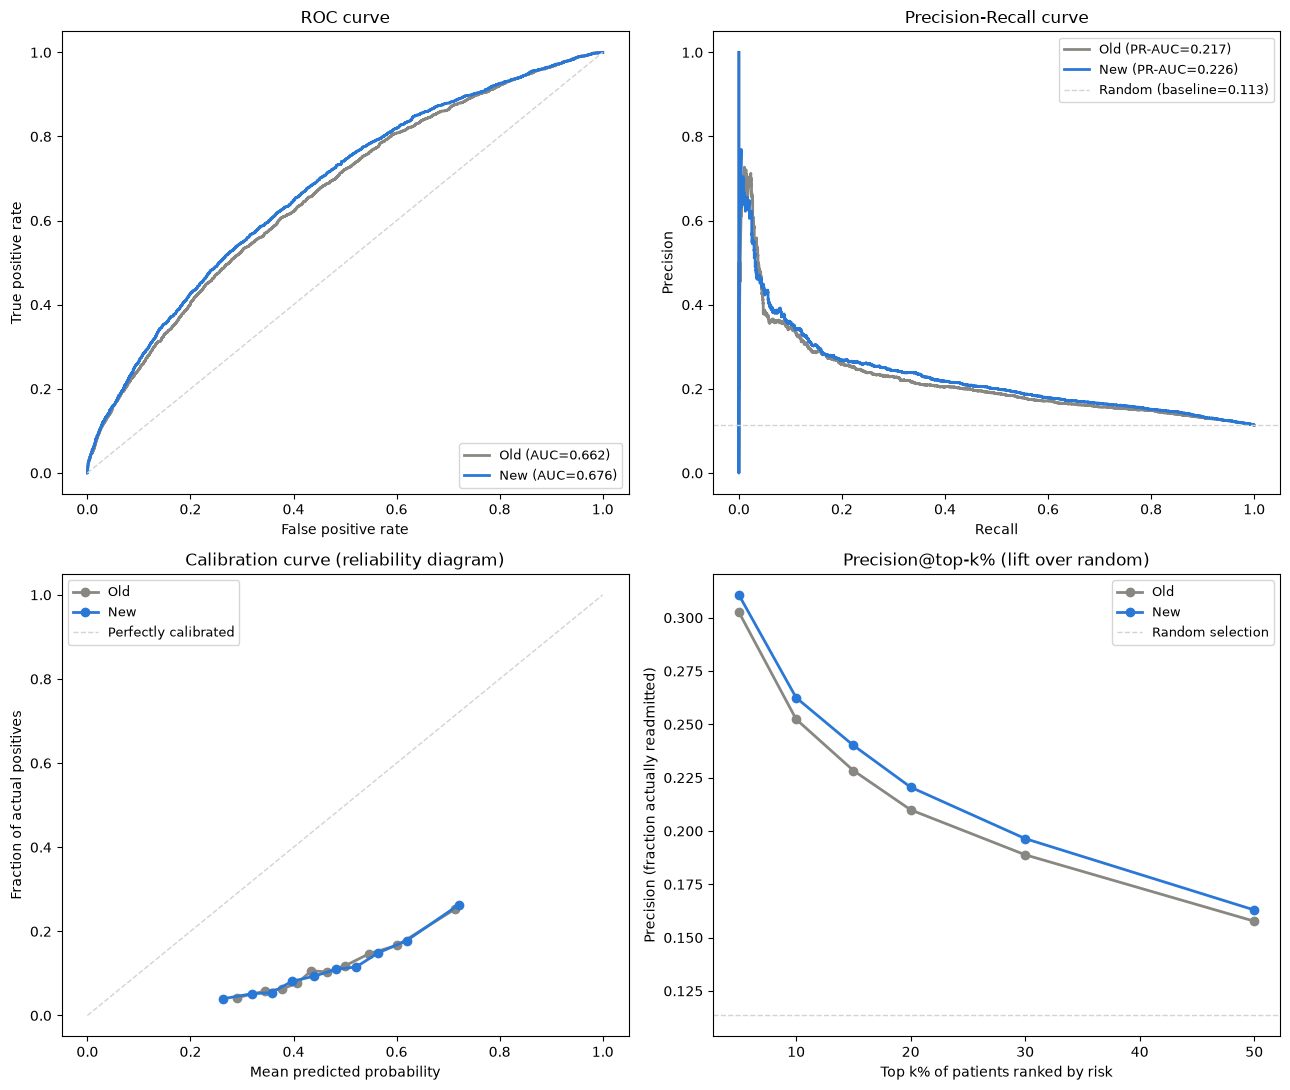

In [2]:
"""
ชุด data visualization เต็มสำหรับเปรียบเทียบ Pipeline เดิม (04) vs Pipeline ใหม่ (05_improved4)

ก่อนรันไฟล์นี้ ต้อง:
1. รัน export_snippet_04.py ต่อท้ายไฟล์ 04_model_training.ipynb ก่อน (export eval_export_04.npz)
2. รัน export_snippet_05.py ต่อท้ายไฟล์ 05_improved_pipeline4.ipynb ก่อน (export eval_export_05.npz)
3. ค่อยรันไฟล์นี้ (แก้ path ให้ตรงกับที่เก็บไฟล์ .npz จริง)

กราฟที่สร้าง (4 กราฟ ครบชุดที่ควรมีสำหรับเปรียบเทียบโมเดล):
1. ROC curve overlay (เก่า vs ใหม่)
2. Precision-Recall curve overlay (เก่า vs ใหม่)
3. Calibration curve / reliability diagram (เก่า vs ใหม่)
4. Precision@top-k% lift chart (เก่า vs ใหม่ vs สุ่ม)
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from sklearn.calibration import calibration_curve

# ---------------------------------------------------------------------------
# โหลดค่าที่ export มาจากทั้งสองไฟล์
# ---------------------------------------------------------------------------
old = np.load("../data/eval_export_04.npz")
new = np.load("../data/eval_export_05.npz")

y_test_old, y_proba_old = old["y_test"], old["y_proba"]
y_test_new, y_proba_new = new["y_test"], new["y_proba"]

COLOR_OLD = "#898781"   # เทา = pipeline เดิม
COLOR_NEW = "#2a78d6"   # น้ำเงิน = pipeline ใหม่

fig, axes = plt.subplots(2, 2, figsize=(13, 11))

# ---------------------------------------------------------------------------
# 1. ROC curve overlay
# ---------------------------------------------------------------------------
ax = axes[0, 0]
fpr_o, tpr_o, _ = roc_curve(y_test_old, y_proba_old)
fpr_n, tpr_n, _ = roc_curve(y_test_new, y_proba_new)
ax.plot(fpr_o, tpr_o, color=COLOR_OLD, lw=2, label=f"Old (AUC={auc(fpr_o, tpr_o):.3f})")
ax.plot(fpr_n, tpr_n, color=COLOR_NEW, lw=2, label=f"New (AUC={auc(fpr_n, tpr_n):.3f})")
ax.plot([0, 1], [0, 1], "--", color="lightgray", lw=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve")
ax.legend(loc="lower right", fontsize=9)

# ---------------------------------------------------------------------------
# 2. Precision-Recall curve overlay
# ---------------------------------------------------------------------------
ax = axes[0, 1]
prec_o, rec_o, _ = precision_recall_curve(y_test_old, y_proba_old)
prec_n, rec_n, _ = precision_recall_curve(y_test_new, y_proba_new)
ax.plot(rec_o, prec_o, color=COLOR_OLD, lw=2,
        label=f"Old (PR-AUC={auc(rec_o, prec_o):.3f})")
ax.plot(rec_n, prec_n, color=COLOR_NEW, lw=2,
        label=f"New (PR-AUC={auc(rec_n, prec_n):.3f})")
baseline_rate = y_test_new.mean()
ax.axhline(baseline_rate, color="lightgray", ls="--", lw=1,
           label=f"Random (baseline={baseline_rate:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curve")
ax.legend(loc="upper right", fontsize=9)

# ---------------------------------------------------------------------------
# 3. Calibration curve (reliability diagram)
# ---------------------------------------------------------------------------
ax = axes[1, 0]
frac_pos_o, mean_pred_o = calibration_curve(y_test_old, y_proba_old, n_bins=10, strategy="quantile")
frac_pos_n, mean_pred_n = calibration_curve(y_test_new, y_proba_new, n_bins=10, strategy="quantile")
ax.plot(mean_pred_o, frac_pos_o, "o-", color=COLOR_OLD, lw=2, label="Old")
ax.plot(mean_pred_n, frac_pos_n, "o-", color=COLOR_NEW, lw=2, label="New")
ax.plot([0, 1], [0, 1], "--", color="lightgray", lw=1, label="Perfectly calibrated")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of actual positives")
ax.set_title("Calibration curve (reliability diagram)")
ax.legend(loc="upper left", fontsize=9)

# ---------------------------------------------------------------------------
# 4. Precision@top-k% lift chart
# ---------------------------------------------------------------------------
def precision_at_k(y_true, y_proba, k_frac):
    n_top = max(1, int(len(y_proba) * k_frac))
    top_idx = np.argsort(y_proba)[::-1][:n_top]
    return y_true[top_idx].mean()

ax = axes[1, 1]
k_fracs = np.array([0.05, 0.10, 0.15, 0.20, 0.30, 0.50])
p_old = [precision_at_k(y_test_old, y_proba_old, k) for k in k_fracs]
p_new = [precision_at_k(y_test_new, y_proba_new, k) for k in k_fracs]
ax.plot(k_fracs * 100, p_old, "o-", color=COLOR_OLD, lw=2, label="Old")
ax.plot(k_fracs * 100, p_new, "o-", color=COLOR_NEW, lw=2, label="New")
ax.axhline(baseline_rate, color="lightgray", ls="--", lw=1, label="Random selection")
ax.set_xlabel("Top k% of patients ranked by risk")
ax.set_ylabel("Precision (fraction actually readmitted)")
ax.set_title("Precision@top-k% (lift over random)")
ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.savefig("../data/full_comparison_dashboard.png", dpi=150, bbox_inches="tight")
print("Saved: full_comparison_dashboard.png")
plt.show()